# Autoregressive Density Model on a Ring of Gaussians

This notebook implements an **autoregressive generative model** from first principles in PyTorch on a two-dimensional ring of Gaussians.

### Learning goals
1. Use the probability chain rule to factorize a joint density.
2. Model multimodal one-dimensional conditionals with mixture density networks.
3. Train with exact maximum likelihood and evaluate exact log densities.
4. Generate samples sequentially, one coordinate at a time.
5. Understand the effect of variable ordering and the likelihood–sampling trade-off.

In two dimensions, the entire autoregressive process can be plotted directly. The same principle later becomes pixel-by-pixel image generation.

## Before you begin

**Prerequisites.** You should know conditional probability and the chain rule, one-dimensional Gaussian mixtures, maximum likelihood, basic neural networks, and PyTorch tensor operations. No masked-network implementation is required for this 2D example.

> **Notation and orientation**
> - A point is ordered as $x=(x_1,x_2)$ and factorized as $p(x_1)p_\theta(x_2\mid x_1)$.
> - $M$ is the number of Gaussian mixture components. Variables $\pi_m$, $\mu_m$, and $\sigma_m$ are their weights, means, and standard deviations.
> - **Density evaluation:** both observed coordinates are available. **Generation:** sample $x_1$ first, then $x_2$ conditionally. The chosen ordering sets this causal computation.

## 1. Setup

Only NumPy, Matplotlib, and PyTorch are required. Training uses a GPU automatically when available.

**Runtime:** This toy model trains directly in the notebook. Expect roughly tens of seconds on a recent GPU and up to a few minutes on CPU. The exact time depends on hardware.


In [1]:
import random
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PLOT_THEME = "light"  # Change to "dark" for the dark plot palette.
if PLOT_THEME not in {"light", "dark"}:
    raise ValueError("PLOT_THEME must be 'light' or 'dark'.")

# Start from Matplotlib defaults so light mode keeps the standard coloring.
plt.style.use("default")
if PLOT_THEME == "dark":
    plt.style.use("dark_background")
    plt.rcParams.update(
        {
            "figure.facecolor": "#0a0f18",
            "figure.edgecolor": "#0a0f18",
            "axes.facecolor": "#111926",
            "axes.edgecolor": "#e8eff9",
            "axes.labelcolor": "#e8eff9",
            "axes.titlecolor": "#e8eff9",
            "text.color": "#e8eff9",
            "xtick.color": "#e8eff9",
            "ytick.color": "#e8eff9",
            "grid.color": "#2b3340",
            "savefig.facecolor": "#0a0f18",
            "savefig.edgecolor": "#0a0f18",
        }
    )

PLOT_REFERENCE_COLOR = "black" if PLOT_THEME == "light" else "#6cd2e8"
PLOT_GENERATED_COLOR = "tab:orange" if PLOT_THEME == "light" else "#f09a4b"
PLOT_GUIDE_COLOR = "black" if PLOT_THEME == "light" else "#e8eff9"

plt.rcParams.update({"figure.figsize": (6, 5), "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
print(f"PyTorch {torch.__version__} | device: {DEVICE}")

PyTorch 2.12.0+cu130 | device: cuda


## 2. Data: a ring of Gaussians

We use an equally weighted mixture of $K$ isotropic Gaussian components:

$$\mu_k=r[\cos(2\pi k/K),\sin(2\pi k/K)]^\top,\qquad
x\mid k\sim\mathcal N(\mu_k,\sigma_{data}^2I).$$

The component labels are retained only for plots. They are never provided to the model.

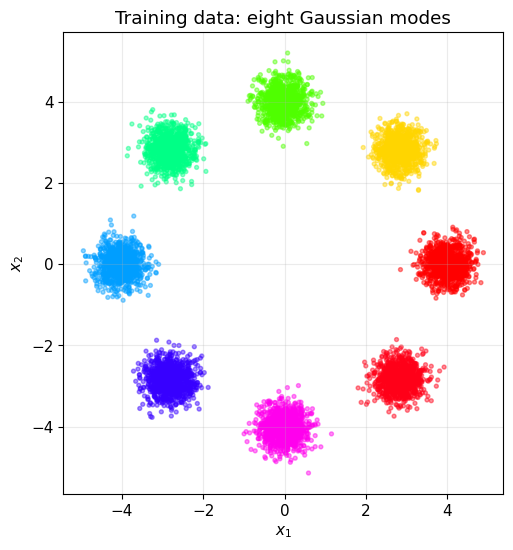

Train shape: (8000, 2)


In [2]:
def sample_ring(n_samples, n_modes=8, radius=4.0, std=0.30, seed=0):
    """Return observations and visualization-only component labels."""
    g = torch.Generator().manual_seed(seed)
    labels = torch.randint(n_modes, (n_samples,), generator=g)
    angles = 2 * torch.pi * labels.float() / n_modes
    centers = radius * torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)
    return centers + std * torch.randn(n_samples, 2, generator=g), labels


N_MODES, RADIUS, DATA_STD = 8, 4.0, 0.30
x_train, y_train = sample_ring(8_000, N_MODES, RADIUS, DATA_STD, SEED)
x_test, y_test = sample_ring(2_000, N_MODES, RADIUS, DATA_STD, SEED + 1)
train_loader = DataLoader(
    TensorDataset(x_train),
    batch_size=512,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x_train[:, 0], x_train[:, 1], c=y_train, cmap="hsv", s=8, alpha=0.45)
ax.set(title="Training data: eight Gaussian modes", xlabel="$x_1$", ylabel="$x_2$")
ax.set_aspect("equal")
plt.show()
print("Train shape:", tuple(x_train.shape))

## 3. The autoregressive factorization

The probability chain rule factorizes any joint density:

$$p(x_1,x_2)=p(x_1)\,p(x_2\mid x_1).$$

In $D$ dimensions,

$$p(x)=\prod_{d=1}^{D}p(x_d\mid x_{<d}),
\qquad
\log p(x)=\sum_{d=1}^{D}\log p(x_d\mid x_{<d}).$$

This gives two important computational properties:

- **Likelihood evaluation is parallel across dimensions** when all observed coordinates are available (with a suitable masked architecture).
- **Sampling is sequential:** first sample $x_1$, then $x_2\mid x_1$, and so on.

For our 2D example, we explicitly use one marginal model and one conditional model. This is the simplest possible autoregressive density estimator.

## 4. Why use mixture conditionals?

A single Gaussian conditional is not expressive enough. For example, around $x_1=0$, the ring places $x_2$ near both $+r$ and $-r$, making $p(x_2\mid x_1)$ strongly bimodal.

We therefore model both factors as mixtures of $M$ Gaussians:

$$p(x_1)=\sum_{m=1}^M\pi_m\,\mathcal N(x_1;\mu_m,\sigma_m^2),$$

$$p_\theta(x_2\mid x_1)=\sum_{m=1}^M\pi_m(x_1)\,
\mathcal N(x_2;\mu_m(x_1),\sigma_m^2(x_1)).$$

The first factor has free learnable parameters. A neural network predicts the conditional mixture parameters for the second factor. This is called a **mixture density network (MDN)**.

In [3]:
LOG_2PI = float(np.log(2 * np.pi))


def gaussian_mixture_log_prob(value, logits, means, log_scales):
    """Log probability under a batch of univariate Gaussian mixtures."""
    value = value.unsqueeze(-1)
    component_log_prob = -0.5 * (
        ((value - means) / log_scales.exp()).square() + 2 * log_scales + LOG_2PI
    )
    return torch.logsumexp(F.log_softmax(logits, dim=-1) + component_log_prob, dim=-1)


def sample_gaussian_mixture(logits, means, log_scales):
    """Draw one differentiability-free sample per mixture in the batch."""
    component = torch.distributions.Categorical(logits=logits).sample()
    chosen_mean = means.gather(-1, component.unsqueeze(-1)).squeeze(-1)
    chosen_log_scale = log_scales.gather(-1, component.unsqueeze(-1)).squeeze(-1)
    return chosen_mean + chosen_log_scale.exp() * torch.randn_like(chosen_mean)


class AutoregressiveMDN(nn.Module):
    def __init__(self, n_components=12, hidden=96):
        super().__init__()
        self.n_components = n_components
        # Parameters of p(x1), independent of any input.
        self.x1_logits = nn.Parameter(torch.zeros(n_components))
        self.x1_means = nn.Parameter(torch.linspace(-4.5, 4.5, n_components))
        self.x1_raw_scales = nn.Parameter(torch.full((n_components,), -0.5))
        # Parameters of p(x2 | x1).
        self.conditioner = nn.Sequential(
            nn.Linear(1, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, 3 * n_components),
        )

    @staticmethod
    def bounded_log_scales(raw):
        # Keep standard deviations in a stable, useful range: approximately [0.05, 2.0].
        return -3.0 + 3.7 * torch.sigmoid(raw)

    def x1_parameters(self, batch_size):
        return (
            self.x1_logits.expand(batch_size, -1),
            self.x1_means.expand(batch_size, -1),
            self.bounded_log_scales(self.x1_raw_scales).expand(batch_size, -1),
        )

    def x2_parameters(self, x1):
        logits, means, raw_scales = self.conditioner(x1.unsqueeze(-1)).chunk(3, dim=-1)
        return logits, means, self.bounded_log_scales(raw_scales)

    def factor_log_probs(self, x):
        x1_logits, x1_means, x1_log_scales = self.x1_parameters(len(x))
        log_p_x1 = gaussian_mixture_log_prob(
            x[:, 0], x1_logits, x1_means, x1_log_scales
        )
        x2_logits, x2_means, x2_log_scales = self.x2_parameters(x[:, 0])
        log_p_x2_given_x1 = gaussian_mixture_log_prob(
            x[:, 1], x2_logits, x2_means, x2_log_scales
        )
        return log_p_x1, log_p_x2_given_x1

    def log_prob(self, x):
        return sum(self.factor_log_probs(x))

    @torch.no_grad()
    def sample(self, n):
        x1_params = self.x1_parameters(n)
        x1 = sample_gaussian_mixture(*x1_params)
        x2 = sample_gaussian_mixture(*self.x2_parameters(x1))
        return torch.stack([x1, x2], dim=-1)


model = AutoregressiveMDN().to(DEVICE)
print(model)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

AutoregressiveMDN(
  (conditioner): Sequential(
    (0): Linear(in_features=1, out_features=96, bias=True)
    (1): Tanh()
    (2): Linear(in_features=96, out_features=96, bias=True)
    (3): Tanh()
    (4): Linear(in_features=96, out_features=36, bias=True)
  )
)
Parameters: 13,032


## 5. Check the probability computations

Before training, we verify shapes, finite log probabilities, normalized mixture weights, and differentiability. The model outputs **logits**, not probabilities. The `log_softmax` operation then gives stable log mixture weights.

In [4]:
example = x_train[:32].to(DEVICE)
log_p1, log_p2 = model.factor_log_probs(example)
loss = -(log_p1 + log_p2).mean()
loss.backward()

conditional_logits, conditional_means, conditional_log_scales = model.x2_parameters(
    example[:, 0]
)
assert log_p1.shape == log_p2.shape == (32,)
assert (
    conditional_logits.shape
    == conditional_means.shape
    == conditional_log_scales.shape
    == (32, 12)
)
assert torch.isfinite(loss)
assert torch.allclose(
    conditional_logits.softmax(-1).sum(-1), torch.ones(32, device=DEVICE)
)
assert all(p.grad is not None for p in model.parameters())
model.zero_grad(set_to_none=True)
print(f"Sanity check passed | initial NLL: {loss.item():.3f} nats")

Sanity check passed | initial NLL: 22.017 nats


## 6. Train by exact maximum likelihood

Because every conditional is normalized, the joint density is normalized. We can directly minimize

$$\mathcal L(\theta)=-\frac1N\sum_i\left[
\log p_\theta(x_1^{(i)})+\log p_\theta(x_2^{(i)}\mid x_1^{(i)})
\right].$$

There is no latent variable, variational bound, discriminator, or Jacobian determinant!

In [5]:
EPOCHS = 200
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
history = {"nll": [], "x1_nll": [], "x2_conditional_nll": []}
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    totals = np.zeros(3)
    for (batch,) in train_loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        log_p1, log_p2 = model.factor_log_probs(batch)
        loss = -(log_p1 + log_p2).mean()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        optimizer.step()
        values = [loss.item(), -log_p1.mean().item(), -log_p2.mean().item()]
        totals += np.array(values) * len(batch)
    averages = totals / len(x_train)
    for key, value in zip(history, averages):
        history[key].append(value)
    if epoch == 1 or epoch % 40 == 0:
        print(
            f"epoch {epoch:3d} | NLL {averages[0]:6.3f} | "
            f"x1 NLL {averages[1]:6.3f} | x2|x1 NLL {averages[2]:6.3f}"
        )
print(f"Training time: {time.time() - start:.1f} s")

epoch   1 | NLL  8.395 | x1 NLL  2.341 | x2|x1 NLL  6.054
epoch  40 | NLL  2.531 | x1 NLL  1.730 | x2|x1 NLL  0.801
epoch  80 | NLL  2.525 | x1 NLL  1.729 | x2|x1 NLL  0.796
epoch 120 | NLL  2.519 | x1 NLL  1.729 | x2|x1 NLL  0.790
epoch 160 | NLL  2.520 | x1 NLL  1.729 | x2|x1 NLL  0.791
epoch 200 | NLL  2.527 | x1 NLL  1.729 | x2|x1 NLL  0.798
Training time: 13.8 s


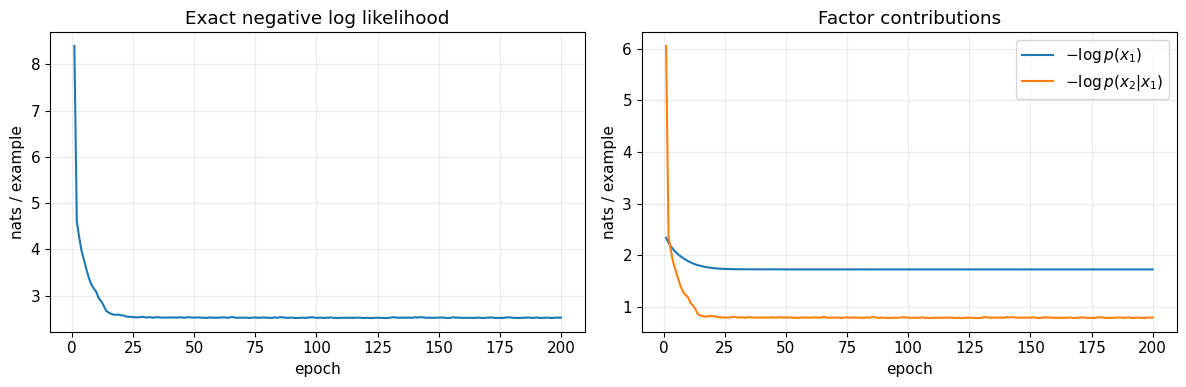

Train NLL: 2.532 nats | test NLL: 2.547 nats


In [6]:
epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["nll"])
axes[0].set(
    xlabel="epoch", ylabel="nats / example", title="Exact negative log likelihood"
)
axes[1].plot(epochs, history["x1_nll"], label=r"$-\log p(x_1)$")
axes[1].plot(epochs, history["x2_conditional_nll"], label=r"$-\log p(x_2|x_1)$")
axes[1].set(xlabel="epoch", ylabel="nats / example", title="Factor contributions")
axes[1].legend()
plt.tight_layout()
plt.show()

model.eval()
with torch.no_grad():
    train_nll = -model.log_prob(x_train.to(DEVICE)).mean().item()
    test_nll = -model.log_prob(x_test.to(DEVICE)).mean().item()
print(f"Train NLL: {train_nll:.3f} nats | test NLL: {test_nll:.3f} nats")

## 7. Inspect the learned factors

The left panel compares the learned marginal $p(x_1)$ with a histogram of observations. The remaining panels show $p(x_2\mid x_1)$ at different selected values of $x_1$.

Near the center of the ring, the conditional must represent distant upper and lower branches. A unimodal Gaussian would average these branches and put density in the empty center.

> **Predict before running.** At $x_1\approx0$, should $p(x_2\mid x_1)$ be unimodal near zero or bimodal near the upper and lower ring branches? How should that conditional change near $x_1\approx4$? **Sketch both predictions and justify them geometrically before running.**

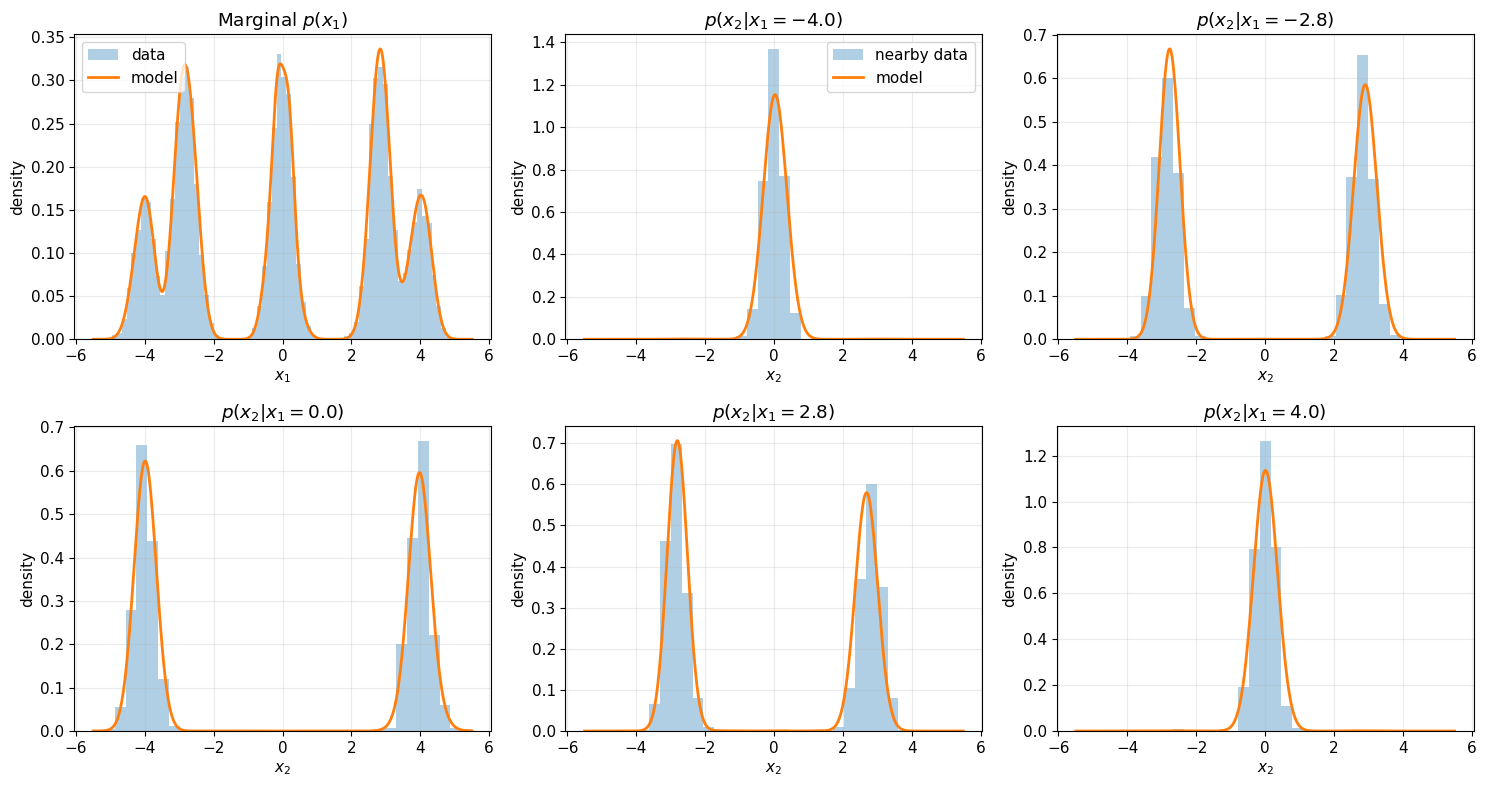

In [7]:
x1_grid = torch.linspace(-5.5, 5.5, 500, device=DEVICE)
x2_grid = torch.linspace(-5.5, 5.5, 500, device=DEVICE)
with torch.no_grad():
    marginal_params = model.x1_parameters(len(x1_grid))
    marginal_density = gaussian_mixture_log_prob(x1_grid, *marginal_params).exp().cpu()

    selected_x1 = torch.tensor([-4.0, -2.8, 0.0, 2.8, 4.0], device=DEVICE)
    conditional_densities = []
    for value in selected_x1:
        repeated = value.expand(len(x2_grid))
        params = model.x2_parameters(repeated)
        conditional_densities.append(
            gaussian_mixture_log_prob(x2_grid, *params).exp().cpu()
        )

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
axes[0].hist(x_train[:, 0].numpy(), bins=70, density=True, alpha=0.35, label="data")
axes[0].plot(x1_grid.cpu(), marginal_density, linewidth=2, label="model")
axes[0].set(title="Marginal $p(x_1)$", xlabel="$x_1$", ylabel="density")
axes[0].legend()
for ax, x1_value, density_curve in zip(
    axes[1:], selected_x1.cpu(), conditional_densities
):
    nearby = (x_train[:, 0] - x1_value).abs() < 0.18
    ax.hist(
        x_train[nearby, 1].numpy(),
        bins=35,
        range=(-5.5, 5.5),
        density=True,
        alpha=0.35,
        label="nearby data",
    )
    ax.plot(x2_grid.cpu(), density_curve, linewidth=2, label="model")
    ax.set(
        title=f"$p(x_2|x_1={x1_value.item():.1f})$", xlabel="$x_2$", ylabel="density"
    )
axes[1].legend()
plt.tight_layout()
plt.show()

> **Expected observation / interpretation.** Near the ring center in $x_1$, the conditional needs separated upper and lower peaks. Near an extreme horizontal coordinate, those branches meet and the conditional narrows toward $x_2\approx0$. The MDN is learning cross-sections of one joint geometry, not eight class labels.

## 8. Generate sequentially

An ancestral sample follows the factorization:

1. sample $x_1\sim p(x_1)$;
2. compute the conditional parameters from the sampled $x_1$;
3. sample $x_2\sim p(x_2\mid x_1)$.

For images, the same loop may contain hundreds or thousands of pixel/channel steps. This sequential dependency is the main sampling bottleneck of autoregressive models.

> **Predict before running.** If $x_1$ is sampled first, can all samples of $x_2$ be generated before any $x_1$ values are known? Predict the resulting mode coverage and identify which operations can still be batched. **Commit to a justification from the factorization.**

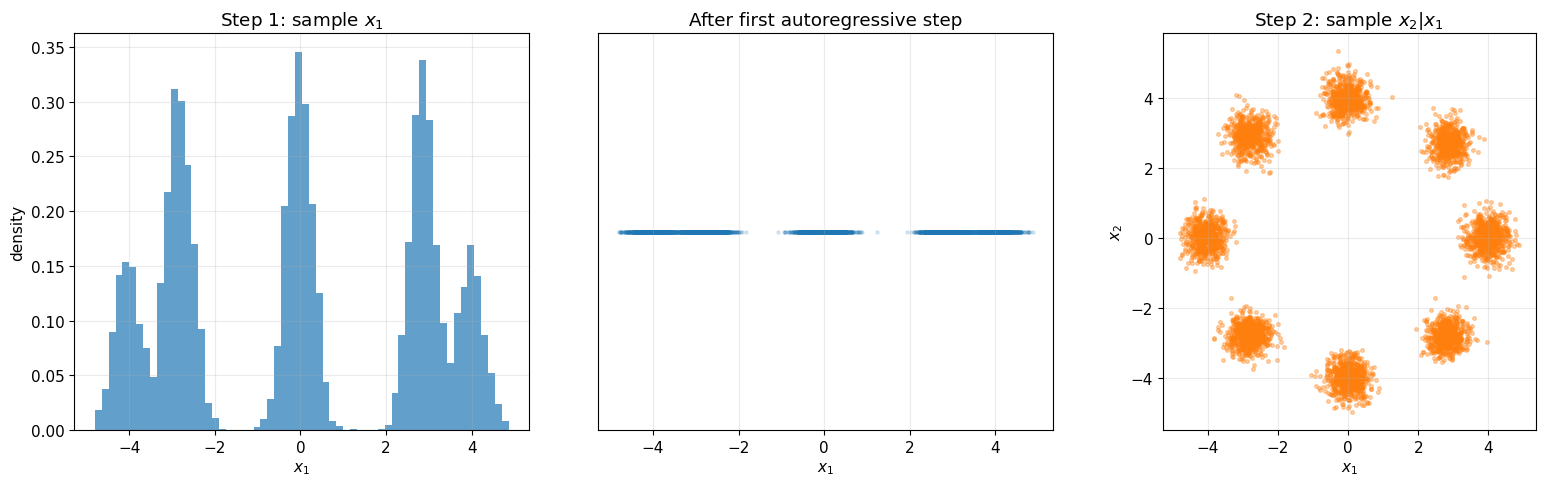

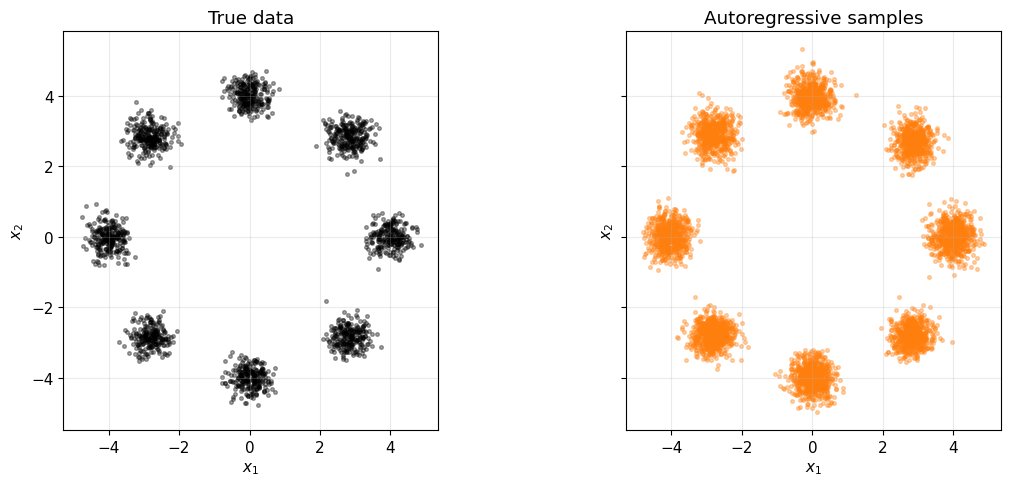

In [8]:
with torch.no_grad():
    generated = model.sample(5_000).cpu()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].hist(
    generated[:, 0].numpy(), bins=60, density=True, alpha=0.7, color="tab:blue"
)
axes[0].set(title="Step 1: sample $x_1$", xlabel="$x_1$", ylabel="density")
axes[1].scatter(generated[:, 0], torch.zeros(len(generated)), s=5, alpha=0.15)
axes[1].set(title="After first autoregressive step", xlabel="$x_1$", yticks=[])
axes[2].scatter(generated[:, 0], generated[:, 1], s=7, alpha=0.35, color=PLOT_GENERATED_COLOR)
axes[2].set(title="Step 2: sample $x_2|x_1$", xlabel="$x_1$", ylabel="$x_2$")
axes[2].set_aspect("equal")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
axes[0].scatter(x_test[:, 0], x_test[:, 1], s=7, alpha=0.35, color=PLOT_REFERENCE_COLOR)
axes[0].set_title("True data")
axes[1].scatter(generated[:, 0], generated[:, 1], s=7, alpha=0.35, color=PLOT_GENERATED_COLOR)
axes[1].set_title("Autoregressive samples")
for ax in axes:
    ax.set(xlabel="$x_1$", ylabel="$x_2$")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

> **Expected observation / interpretation.** Sampling is sequential across coordinates but parallel across examples. The batch of $x_1$ values is drawn together, then all corresponding conditionals produce $x_2$. Good ring coverage shows that local conditional choices compose into a global joint sampler.

## 9. Exact learned joint density

The factorization gives exact density values at arbitrary locations:

$$\log p(x_1,x_2)=\log p(x_1)+\log p(x_2\mid x_1).$$

The first plot shows the learned joint density. The second isolates the conditional density, making its dependence on $x_1$ explicit.

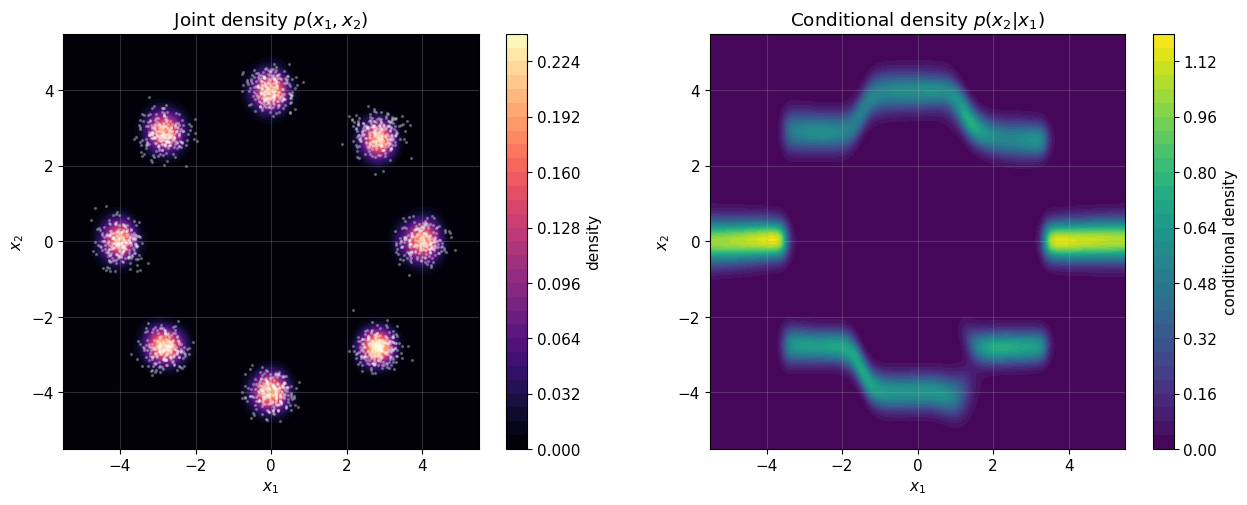

In [9]:
limit, resolution = 5.5, 180
axis = torch.linspace(-limit, limit, resolution)
xx, yy = torch.meshgrid(axis, axis, indexing="xy")
grid = torch.stack([xx.ravel(), yy.ravel()], dim=1)
log_prob_parts, conditional_parts = [], []
with torch.no_grad():
    for chunk in grid.split(4096):
        log_p1, log_p2 = model.factor_log_probs(chunk.to(DEVICE))
        log_prob_parts.append((log_p1 + log_p2).cpu())
        conditional_parts.append(log_p2.cpu())
log_density = torch.cat(log_prob_parts).reshape(resolution, resolution)
conditional_density = torch.cat(conditional_parts).reshape(resolution, resolution).exp()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
filled = axes[0].contourf(xx, yy, log_density.exp(), levels=30, cmap="magma")
axes[0].scatter(x_test[:, 0], x_test[:, 1], s=2, color="white", alpha=0.25)
axes[0].set(title="Joint density $p(x_1,x_2)$", xlabel="$x_1$", ylabel="$x_2$")
fig.colorbar(filled, ax=axes[0], label="density")
conditional_plot = axes[1].contourf(
    xx, yy, conditional_density, levels=30, cmap="viridis"
)
axes[1].set(title="Conditional density $p(x_2|x_1)$", xlabel="$x_1$", ylabel="$x_2$")
fig.colorbar(conditional_plot, ax=axes[1], label="conditional density")
for ax in axes:
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 10. Variable ordering matters computationally

The chain rule is valid in either order:

$$p(x_1,x_2)=p(x_1)p(x_2\mid x_1)=p(x_2)p(x_1\mid x_2).$$

With unlimited capacity both factorizations can represent the same joint density. With finite networks, optimization and approximation quality can differ. More importantly, ordering decides the generation sequence.

For this symmetric dataset, swapping coordinates should make little difference. For images, raster order, channel order, and architectural masks encode stronger inductive biases.

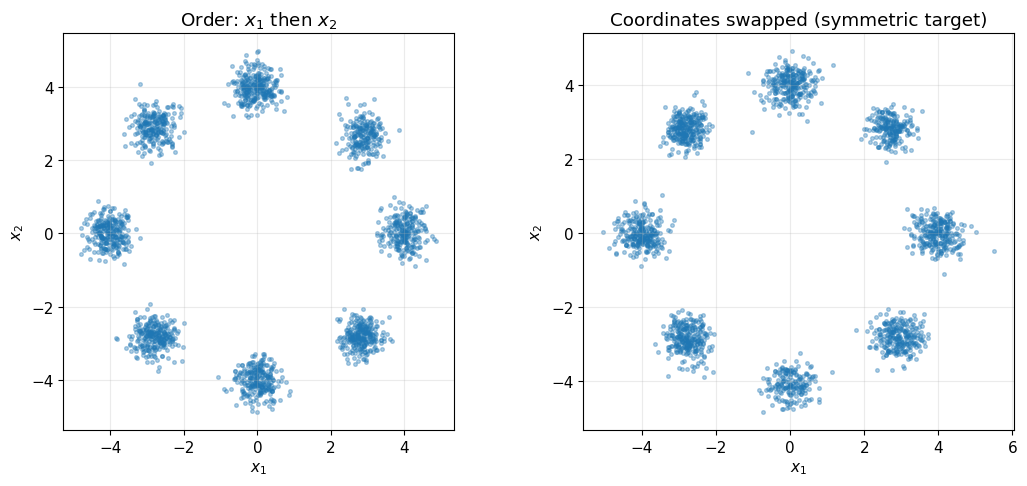

In [10]:
# The existing model generates x1 first. Swapping coordinates illustrates the alternative order
# without training a second model: on this symmetric ring, the target distribution is unchanged.
with torch.no_grad():
    alternative_order_samples = model.sample(2_000).cpu()[:, [1, 0]]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].scatter(generated[:2000, 0], generated[:2000, 1], s=7, alpha=0.35)
axes[0].set_title("Order: $x_1$ then $x_2$")
axes[1].scatter(
    alternative_order_samples[:, 0], alternative_order_samples[:, 1], s=7, alpha=0.35
)
axes[1].set_title("Coordinates swapped (symmetric target)")
for ax in axes:
    ax.set(xlabel="$x_1$", ylabel="$x_2$")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 11. Quantitative toy diagnostics

As in the preceding notebooks, we measure nearest-mode frequencies, radial error, and the fraction of samples farther than three data standard deviations from every center. These are diagnostics, not universal evaluation metrics.

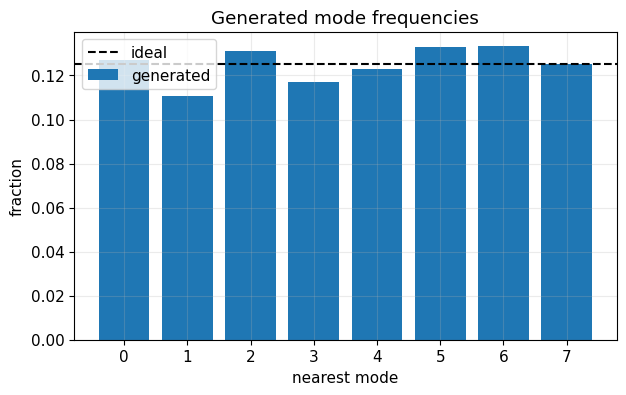

Mean absolute radial error: 0.250
Fraction >3σ from every mode: 2.0%
Modes receiving at least 1% of samples: 8/8


In [11]:
angles = 2 * torch.pi * torch.arange(N_MODES) / N_MODES
centers = RADIUS * torch.stack([torch.cos(angles), torch.sin(angles)], 1)
nearest_distance, nearest_mode = torch.cdist(generated, centers).min(1)
frequencies = torch.bincount(nearest_mode, minlength=N_MODES) / len(generated)
radial_error = (generated.norm(dim=1) - RADIUS).abs().mean()
gap_rate = (nearest_distance > 3 * DATA_STD).float().mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(N_MODES), frequencies.numpy(), label="generated")
ax.axhline(1 / N_MODES, color=PLOT_GUIDE_COLOR, linestyle="--", label="ideal")
ax.set(
    xlabel="nearest mode",
    ylabel="fraction",
    title="Generated mode frequencies",
    xticks=range(N_MODES),
)
ax.legend()
plt.show()
print(f"Mean absolute radial error: {radial_error:.3f}")
print(f"Fraction >3σ from every mode: {gap_rate:.1%}")
print(
    f"Modes receiving at least 1% of samples: {(frequencies > .01).sum().item()}/{N_MODES}"
)

## 12. From two coordinates to MNIST pixels

For a $28\times28$ binary image, we can flatten pixels in a chosen order and write

$$p(x)=\prod_{i=1}^{784}p(x_i\mid x_{<i}).$$

A naive implementation would call a separate network 784 times. Architectures such as **MADE** and **PixelCNN** use masks so one forward pass computes all training conditionals without seeing future pixels. Sampling remains sequential unless specialized parallel-generation methods are used.

For grayscale pixels, common output distributions include categorical distributions over 256 values or discretized logistic mixtures. For binarized MNIST, each conditional can simply be Bernoulli.

## 13. Takeaways and homework experiments

### Takeaways
- The chain rule turns joint density estimation into conditional prediction.
- Exact likelihood training requires every conditional to be normalized.
- Mixture conditionals are essential when a slice through the data is multimodal.
- Likelihood evaluation is direct, while ancestral generation is sequential.
- Variable order is mathematically arbitrary but computationally consequential.
- Unlike a flow, an autoregressive model need not be invertible or preserve dimensionality.

### Mini-experiment 1 — Set `n_components=1`
- **Hypothesis:** A unimodal conditional averages the upper and lower branches around $x_1\approx0$, placing density and samples in the low-density center.
- **Metric/plot:** Plot learned conditionals at the same probe values and the exact joint density. Compare test NLL and off-mode fraction with the baseline.
- **Controls:** Keep the conditioner, data, seed, optimizer, epochs, and evaluation grids fixed. Change only `n_components`.
- **Interpretation:** Central density and worse NLL support the need for multimodal conditionals. If not, inspect whether the conditioner or marginal is compensating elsewhere.

### Mini-experiment 2 — Sweep 2, 4, 8, and 16 components
- **Hypothesis:** Test NLL improves until the mixture can represent relevant conditional branches, then plateaus or becomes harder to optimize.
- **Metric/plot:** Plot test NLL versus component count and report mode coverage/off-mode fraction. Include conditional curves for the best and worst settings.
- **Controls:** Use identical train/test data, seeds, conditioner width, training budget, optimizer, and evaluation samples for every count.
- **Interpretation:** A plateau marks sufficient conditional capacity. A train/test gap or unstable tiny scales at high counts indicates over-parameterization or optimization issues. 

### Extensions
- Reduce conditioner width and inspect underfitting.
- Visualize mixture weights and means as continuous functions of $x_1$.
- Train a second model on swapped coordinates to compare finite-capacity effects.
- Replace Gaussian components with logistic components.

## Exit ticket

1. Factorize $p(x_1,x_2)$ and explain why normalized factors produce a normalized exact joint density.
2. Why is a mixture conditional needed near $x_1=0$ for this ring, and what failure would one Gaussian cause?
3. Contrast likelihood evaluation with ancestral sampling, including the role of variable ordering.

<details>
<summary><strong>Self-check answers</strong></summary>

1. $p(x_1,x_2)=p(x_1)p(x_2\mid x_1)$. Integrating the normalized conditional over $x_2$ gives one, then integrating the normalized marginal over $x_1$ also gives one.
2. The vertical slice intersects upper and lower ring branches, so the conditional is bimodal. One Gaussian tends to average them and assign density near the empty center.
3. Evaluation can condition on all observed previous coordinates and sum exact factor log-probabilities. The generation step must sample in order because later conditionals require earlier samples. A different ordering changes the sequence and finite-capacity inductive bias, not the chain rule.

</details>

## References and further reading

- [Larochelle & Murray, *The Neural Autoregressive Distribution Estimator* (AISTATS 2011)](https://proceedings.mlr.press/v15/larochelle11a.html): Introduces a foundational neural autoregressive density estimator based on the probability-chain-rule factorization used here.
- [van den Oord et al., *Pixel Recurrent Neural Networks* (ICML 2016)](https://proceedings.mlr.press/v48/oord16.html): Shows how the same sequential factorization scales to image pixels and motivates the likelihood–sampling trade-off.